# Neuron Model and Network Architecture

1. Single-Input Neuron
2. Transfer Functions
3. Multiple-Input Neuron
4. Layer of Neurons
5. Abbreviated Notation
6. Multilayer Network
7. Abreviated Notation
8. Delays and Integrators
9. Recurrent Network

## 1. Single-Input Neuron


![](images/single_input_neuron.png)

 $$\displaystyle \LARGE \text{p = Scalar Input      }$$
 $$\displaystyle \LARGE \text{w = Scalar Weight}$$
 $$\displaystyle \LARGE \text{b = Bias}$$
 $$\displaystyle \LARGE \text{n = Net Input}$$
 $$\displaystyle \LARGE \text{f = Transfer function}$$
 $$\displaystyle \LARGE \text{a = Scalar output     }$$


![](images/single_input_neuron_statement.png)

In [24]:
#p = Scalar Input 
#w = Scalar Weight   
#b = Bias             
#n = Net Input         
#f = Transfer function 
#a = Scalar output

In [7]:
p = 2
w = 3
b = -1.5

def f(p=0,w=1,b=1):
    return p*w + b
    

a = f(p,w,b)
a



4.5

## 2. Transfer Functions


 1. Hard Limit
 2. Symmetrical Hard Limit
 3. Linear
 4. Saturating Linear
 5. Symmetric Saturating Linear
 6. Log-Sigmoid
 7. Hyperbolic Tangent Sigmoid
 8. Positive Linear
 9. Competitive

### 1. Hard Limit


$$
\operatorname{hardlim}(x)=
\begin{cases}
0 & x<0\\
1 & x\geq 0
\end{cases}
$$



In [33]:
def hardlim(n):
   return (n>=0).astype(int)

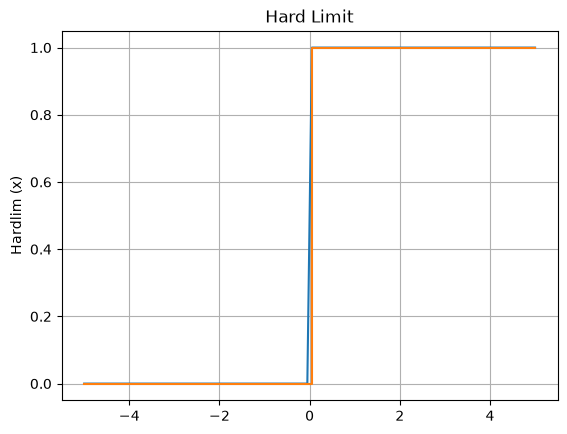

In [143]:
import matplotlib.pyplot as plt
import numpy as np

x = np.linspace(-5,5,100)
y = hardlim(x)
plt.plot(x,y)
plt.step(x, y, where="post")
plt.title("Hard Limit")
plt.ylabel("Hardlim (x)")
plt.grid(True)
plt.show()


 ### 2. Symmetrical Hard Limit

 
$$
\operatorname{hardlims}(x)=
\begin{cases}
-1 & x<0\\
+1 & x\geq 0
\end{cases}
$$


 

In [140]:
def hardlims(x):
   return (x>=0)*1 + (x<0)*-1

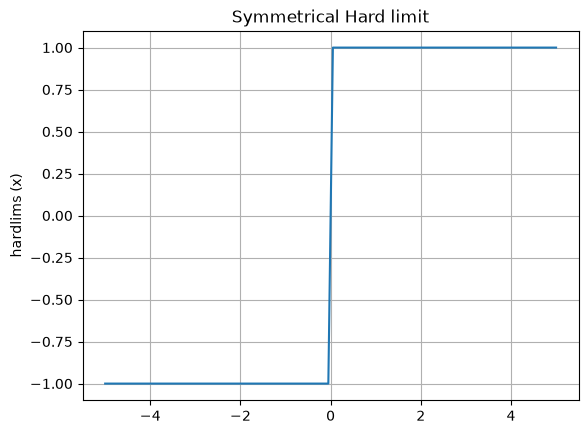

In [142]:
import matplotlib.pyplot as plt
import numpy as np

x = np.linspace(-5,5,100)
y = hardlims(x)

#%timeit hardlims(x)

plt.plot(x, y)
plt.title("Symmetrical Hard limit")
plt.ylabel("hardlims (x)")
plt.grid(True)
plt.show()


### 3. Linear

$$
a = n
$$



In [138]:
def purelin(x):
    return x


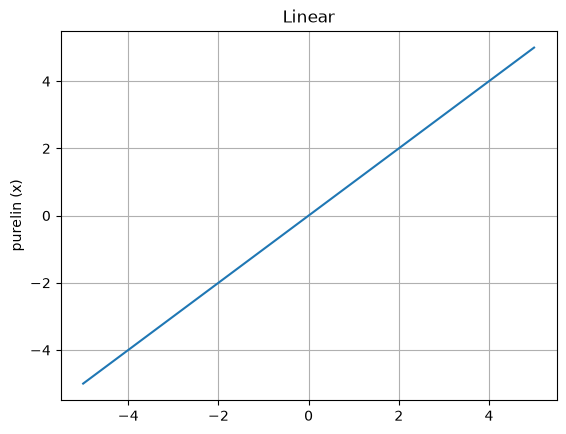

In [139]:
import matplotlib.pyplot as plt
import numpy as np

x = np.linspace(-5,5,100)
y = purelin(x)

#%timeit purelin(x)

plt.plot(x, y)
plt.title("Linear")
plt.ylabel("purelin (x)")
plt.grid(True)
plt.show()


### 4. Saturating Linear


$$
\operatorname{satlin}(x)=
\begin{cases}
0 & x<0\\
x & 0\leq x \leq 1 \\
1 & x > 1
\end{cases}
$$



In [136]:
def satlin(x):
    return ((x >= 0) & (x <= 1)) * x + (x < 0) * 0 + (x > 1) * 1


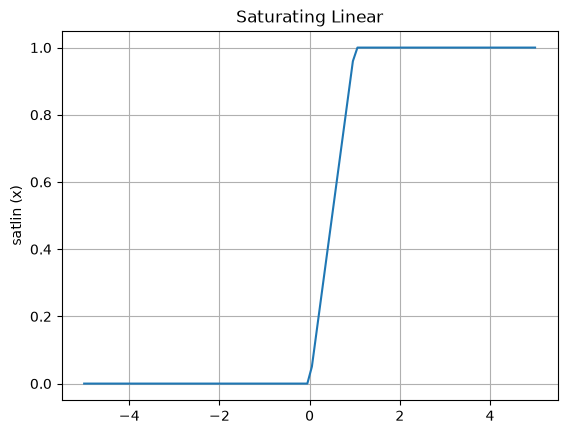

In [137]:
import matplotlib.pyplot as plt
import numpy as np

x = np.linspace(-5,5,100)
y = satlin(x)

#%timeit satlin(x)

plt.plot(x, y)
plt.title("Saturating Linear")
plt.ylabel("satlin (x)")
plt.grid(True)
plt.show()


### 5. Symmetric Saturating Linear

$$
\operatorname{satlins}(x)=
\begin{cases}
-1 & x< -1 \\
x & -1 \leq x \leq 1 \\
1 & x > 1
\end{cases}
$$


In [133]:
def satlins(x):
    return ((x >= -1) & (x <= 1)) * x + (x < -1) * -1 + (x > 1) * 1


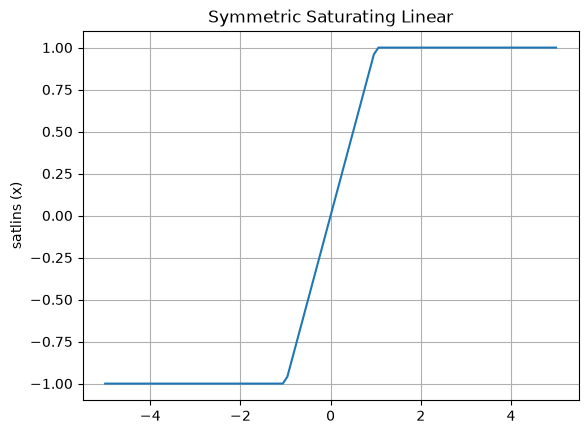

In [135]:
import matplotlib.pyplot as plt
import numpy as np

x = np.linspace(-5,5,100)
y = satlins(x)

#%timeit satlins(x)

plt.plot(x, y)
plt.title("Symmetric Saturating Linear")
plt.ylabel("satlins (x)")
plt.grid(True)
plt.show()


### 6. Log-Sigmoid

$$
\operatorname{logsig}(x)=
\frac{1}{1+e^{-n}}
$$


In [130]:
import math

def logsig(x):
    #return 1 / (1 + (math.e**(-x)))
    return 1 / (1 + np.exp(-x))
    

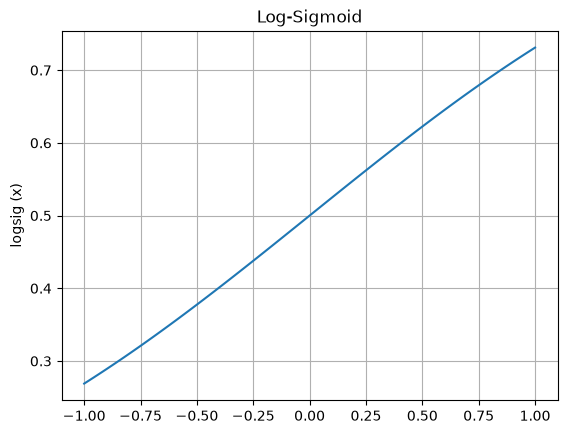

In [131]:
import matplotlib.pyplot as plt
import numpy as np

x = np.linspace(-1,1,100)
y = logsig(x)

#%timeit logsig(x)

plt.plot(x, y)
plt.title("Log-Sigmoid")
plt.ylabel("logsig (x)")
plt.grid(True)
plt.show()


### 7. Hyperbolic Tangent Sigmoid

$$
\operatorname{tansig}(x)=
\frac{e^n - e^{-n}}{e^n + e^{-n}}
$$


In [99]:
import math

def tansig(x):
    #return ((math.e**x) - (math.e**(-x)))/((math.e**x) + (math.e**(-x)))
    #return (np.exp(x) - np.exp(-x)) / (np.exp(x) + np.exp(-x))
    return np.tanh(x)

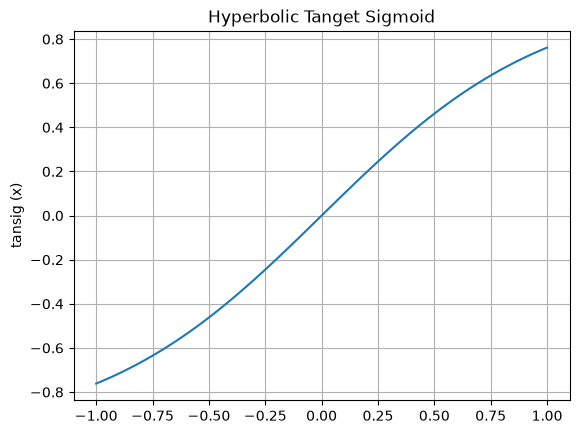

In [101]:
import matplotlib.pyplot as plt
import numpy as np

x = np.linspace(-1,1,100)
y = tansig(x)

#%timeit poslin(x)

plt.plot(x, y)
plt.title("Hyperbolic Tanget Sigmoid")
plt.ylabel("tansig (x)")
plt.grid(True)
plt.show()


### 8. Positive Linear

$$
\operatorname{poslin}(x)=
\begin{cases}
0 & x<0 \\
x & 0 \leq x
\end{cases}
$$



In [84]:
def poslin(x):
    return (x >= 0) * x

966 ns ± 8.34 ns per loop (mean ± std. dev. of 7 runs, 1,000,000 loops each)


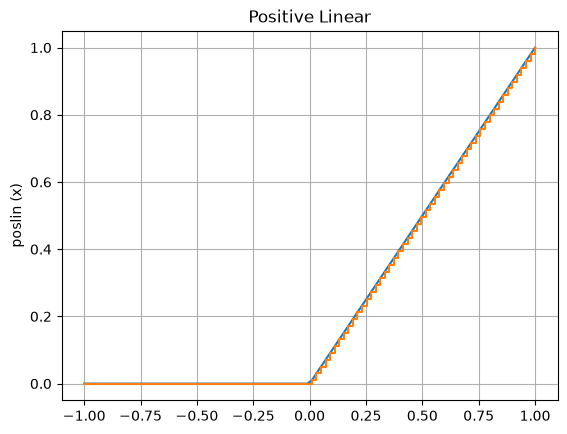

In [89]:
import matplotlib.pyplot as plt
import numpy as np

x = np.linspace(-1,1,100)
y = poslin(x)
%timeit poslin(x)

plt.plot(x, y)
plt.step(x, y, where="post")
plt.title("Positive Linear")
plt.ylabel("poslin (x)")
plt.grid(True)
plt.show()


### 9. Competitive
$$
\operatorname{compet}(x)=
\begin{cases}
1 & \text{neuron with max n}\\
0 & \text{all other neurons}
\end{cases}
$$


In [81]:
def compet(n):
    y = np.zeros_like(n, dtype=int)
    y[np.argmax(x)] = 1
    return y

1.36 μs ± 10.3 ns per loop (mean ± std. dev. of 7 runs, 1,000,000 loops each)


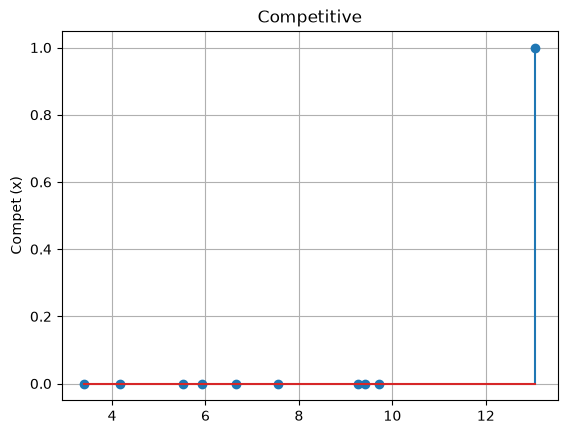

In [83]:
import matplotlib.pyplot as plt
import numpy as np
np.random.seed(123)

#x = np.random.rand(100)
x = np.random.uniform(low=0.5, high=13.3, size=(10,))

y = compet(x)
#plt.hist2d(x,y)
%timeit compet(x)

plt.stem(x, y)
#plt.bar(x, y)
#plt.scatter(x,y)
#plt.step(x, y, where="post")
plt.title("Competitive")
plt.ylabel("Compet (x)")
plt.grid(True)
plt.show()
